##   Data Preprocessing

In [1]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder

In [2]:
df = pd.read_stata(r'C:\Users\Administrator\Downloads\abbay-basin_2.dta', 
                   columns=['hhid', 'hv270', 'hv206', 'hv201', 'hv205', 'hv213', 'UrbanRural', 'Latitude', 'Longitude'])

In [3]:
df = df.dropna()

In [17]:
df=df head()

SyntaxError: invalid syntax (<ipython-input-17-0710ed187670>, line 1)

In [4]:
le = LabelEncoder()
categorical_cols = ['hv206', 'hv201', 'hv205', 'hv213', 'UrbanRural', 'hv270']

for col in categorical_cols:
    if col in df.columns:
        df[col] = le.fit_transform(df[col])

print("Data Preprocessing ተጠናቋል! አጠቃላይ የሰንጠረዥ መጠን:", df.shape)

Data Preprocessing ተጠናቋል! አጠቃላይ የሰንጠረዥ መጠን: (2882, 9)


##  Feature Selection & Train-Test Split

In [5]:
from sklearn.model_selection import train_test_split
X = df[['hv206', 'hv201', 'hv205', 'hv213', 'UrbanRural', 'Latitude', 'Longitude']]
y = df['hv270']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Train shape: (2305, 7)
Test shape: (577, 7)


##  Model Training & Evaluation

In [6]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Model Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Model Accuracy: 0.6135181975736569

Classification Report:
               precision    recall  f1-score   support

           0       0.48      0.49      0.49       130
           1       0.48      0.50      0.49       117
           2       0.73      0.69      0.71       107
           3       0.58      0.57      0.57       120
           4       0.86      0.87      0.87       103

    accuracy                           0.61       577
   macro avg       0.63      0.62      0.62       577
weighted avg       0.62      0.61      0.61       577



 ##  Model Saving

In [7]:
import pickle

# ሞዴሉን በ Desktop ላይ 'wealth_model.pkl' በሚል ስም ማስቀመጥ
desktop_path = r'C:\Users\Administrator\Desktop\wealth_model.pkl'

with open(desktop_path, 'wb') as file:
    pickle.dump(model, file)

print("ሞዴሉ በ Desktop ላይ በተሳካ ሁኔታ ተቀምጧል!")

ሞዴሉ በ Desktop ላይ በተሳካ ሁኔታ ተቀምጧል!


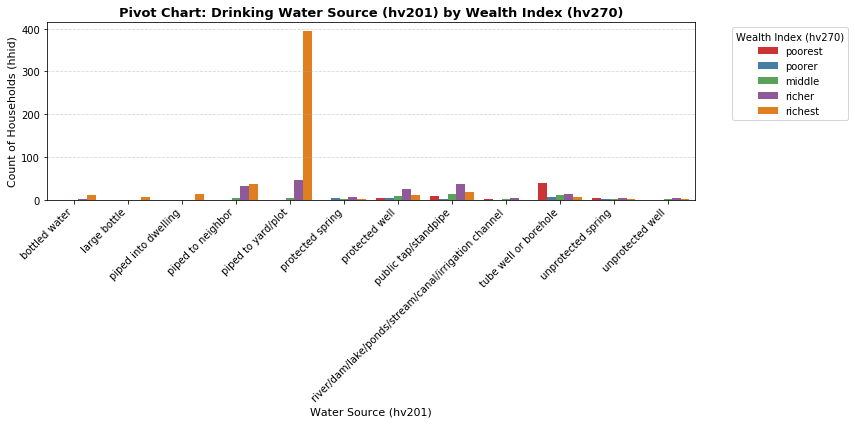

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. የኤክሴል ፋይሉን ከ Desktop ማንበብ
file_path = r'C:\Users\Administrator\Desktop\Asmarech.xlsx'
df_raw = pd.read_excel(file_path)

# 2. ሰንጠረዡን ማጽዳት እና ማስተካከል (Pivot Table መዋቅር መፍጠር)
# ከኤክሴል ሰንጠረዥ ውስጥ ርዕሶቹን እና አጠቃላይ ድምርን በመተው ትክክለኛውን መረጃ መምረጥ
df_clean = df_raw.iloc[3:15, [0, 1, 2, 3, 4, 5]].copy()
df_clean.columns = ['hv201', 'middle', 'poorer', 'poorest', 'richer', 'richest']
df_clean.fillna(0, inplace=True)

# ቁጥሮቹን ወደ ትክክለኛ የቁጥር (Numeric) ዓይነት መቀየር
wealth_cols = ['middle', 'poorer', 'poorest', 'richer', 'richest']
for col in wealth_cols:
    df_clean[col] = df_clean[col].astype(float)

# 3. ዳታውን ከሰፊ (Wide) ወደ ረጅም (Long) ቅርጸት መቀየር (ለግራፍ ማውጫ እንዲመች)
df_long = df_clean.melt(id_vars=['hv201'], var_name='hv270', value_name='Count')

# የሀብት ደረጃዎቹን ቅደም ተከተል ከድሃ እስከ ሀብታም ማስተካከል
wealth_order = ['poorest', 'poorer', 'middle', 'richer', 'richest']
df_long['hv270'] = pd.Categorical(df_long['hv270'], categories=wealth_order, ordered=True)

# 4. Pivot Chart (Stacked/Grouped Bar Chart) መሳል
plt.figure(figsize=(12, 6))
sns.barplot(data=df_long, x='hv201', y='Count', hue='hv270', palette='Set1')

plt.title('Pivot Chart: Drinking Water Source (hv201) by Wealth Index (hv270)', fontsize=13, fontweight='bold')
plt.xlabel('Water Source (hv201)', fontsize=11)
plt.ylabel('Count of Households (hhid)', fontsize=11)
plt.xticks(rotation=45, ha='right')
plt.legend(title='Wealth Index (hv270)', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

##  Model Interpretability & Visualization

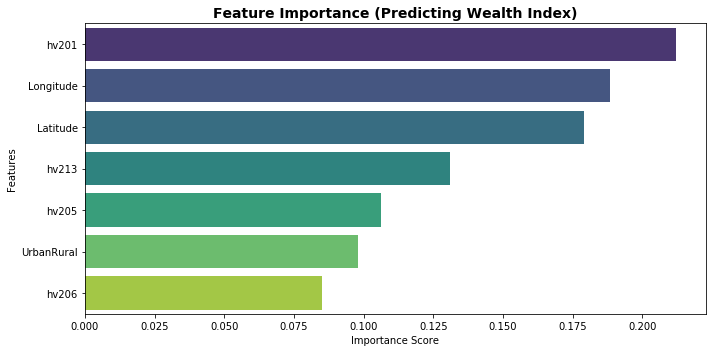

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

# 1. Feature Importance
importances = model.feature_importances_
feature_names = X.columns
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(10, 5))
sns.barplot(x=importances[indices], y=feature_names[indices], palette="viridis")
plt.title("Feature Importance (Predicting Wealth Index)", fontsize=14, fontweight='bold')
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

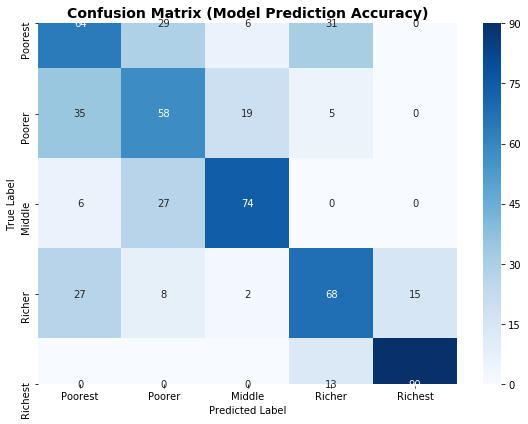

In [11]:
# 2. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Poorest', 'Poorer', 'Middle', 'Richer', 'Richest'],
            yticklabels=['Poorest', 'Poorer', 'Middle', 'Richer', 'Richest'])
plt.title("Confusion Matrix (Model Prediction Accuracy)", fontsize=14, fontweight='bold')
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

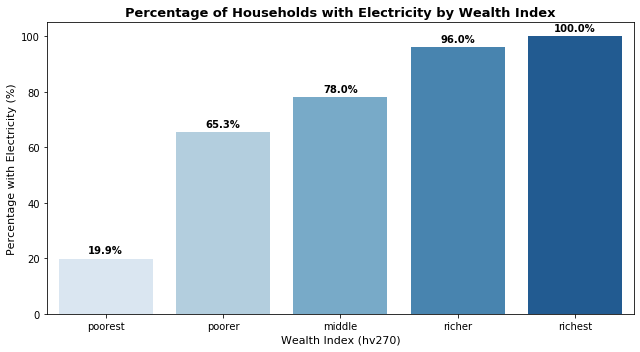

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ዳታውን ማንበብ
df = pd.read_excel(r'C:\Users\Administrator\Desktop\Enanu.xlsx')
wealth_order = ['poorest', 'poorer', 'middle', 'richer', 'richest']

# የኤሌክትሪክ አገልግሎት መቶኛ በሀብት ደረጃ
elec_pct = pd.crosstab(df['hv270'], df['hv206'], normalize='index')[['yes']] * 100
elec_pct = elec_pct.loc[wealth_order]

# ግራፉን መሳል (palette='Blues' በመጠቀም)
plt.figure(figsize=(9, 5))
ax = sns.barplot(x=elec_pct.index, y=elec_pct['yes'], palette='Blues')
plt.title('Percentage of Households with Electricity by Wealth Index', fontsize=13, fontweight='bold')
plt.xlabel('Wealth Index (hv270)', fontsize=11)
plt.ylabel('Percentage with Electricity (%)', fontsize=11)
plt.ylim(0, 105)

for i, v in enumerate(elec_pct['yes']):
    ax.text(i, v + 2, f"{v:.1f}%", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

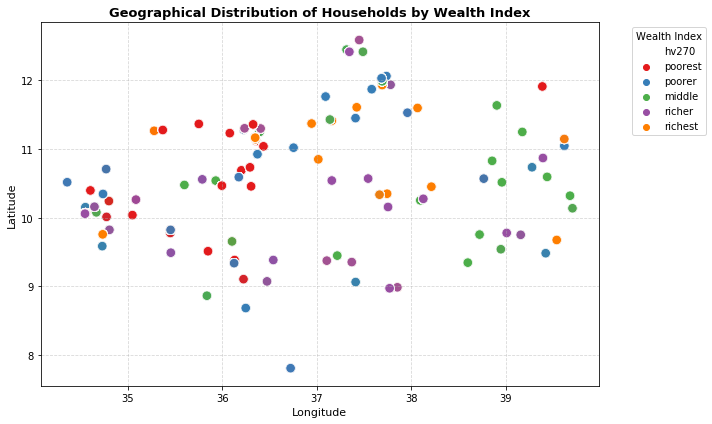

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# የሀብት ደረጃዎች ቅደም ተከተል
wealth_order = ['poorest', 'poorer', 'middle', 'richer', 'richest']

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df, x='Longitude', y='Latitude', 
    hue='hv270', hue_order=wealth_order, 
    palette='Set1', alpha=0.9, s=90
)

plt.title('Geographical Distribution of Households by Wealth Index', fontsize=13, fontweight='bold')
plt.xlabel('Longitude', fontsize=11)
plt.ylabel('Latitude', fontsize=11)
plt.legend(title='Wealth Index', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Deployment

In [15]:
import streamlit as st
import pickle
import numpy as np

# የተቀመጠውን ሞዴል መጫን
model_path = r'C:\Users\Administrator\Desktop\wealth_model.pkl'
model = pickle.load(open(model_path, 'rb'))

st.title("የቤተሰብ ሀብት ደረጃ (Wealth Index) መተንበያ ስርዓት")

st.sidebar.header("የቤተሰብ መረጃዎችን ያስገቡ")

# ለተጠቃሚው መስጫዎችን (Inputs) ማዘጋጀት
hv206 = st.sidebar.selectbox("ኤሌክትሪክ አገልግሎት አላቸው? (0=No, 1=Yes)", [0, 1])
hv201 = st.sidebar.slider("የመጠጥ ውሃ ምንጭ (ኮድ)", 0, 10, 2)
hv205 = st.sidebar.slider("የሽንት ቤት ዓይነት (ኮድ)", 0, 10, 1)
hv213 = st.sidebar.slider("የቤት ወለል ዓይነት (ኮድ)", 0, 10, 1)
UrbanRural = st.sidebar.selectbox("የኑሮ አካባቢ (0=Rural, 1=Urban)", [0, 1])
Latitude = st.sidebar.number_input("Latitude (ኬክሮስ)", 9.0)
Longitude = st.sidebar.number_input("Longitude (ኬንሮስ)", 37.0)

# ተጠቃሚው ቁልፉን ሲጫን
if st.button("የሀብት ደረጃን ተንብይ"):
    input_data = np.array([[hv206, hv201, hv205, hv213, UrbanRural, Latitude, Longitude]])
    prediction = model.predict(input_data)
    
    # የቁጥር ኮዱን ወደ ግልጽ ቃላት መለወጥ (Mapping)
    # ማስታወሻ፡ በስታታ ዳታዎ መሰረት የቁጥሮቹን ትርጉም እዚህ ማስተካከል ይቻላል
    wealth_labels = {
        0: "በጣም ድሃ (Poorest)",
        1: "ድሃ (Poorer)",
        2: "መካከለኛ (Middle)",
        3: "ሀብታም (Richer)",
        4: "በጣም ሀብታም (Richest)"
    }
    
    # የተገኘውን ቁጥር ከቃላቱ ጋር ማዛመድ (ቁጥሩ በ dictionary ውስጥ ከሌለ በቀጥታ ቁጥሩን ያሳያል)
    predicted_label = wealth_labels.get(int(prediction[0]), f"ምድብ ቁጥር: {prediction[0]}")
    
    st.success(f"የተገመተው የቤተሰብ ሀብት ደረጃ: **{predicted_label}**")